# **Anexo Step 6 – Clustering nutricional (z OMS)**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 6:* «Choosing the data mining algorithms: which models and parameters may be appropriate for searching for patterns (e.g. models for categorical data or models on vectors over the reals).»

> **Por qué es un anexo.** Fue el primer intento de clustering: agrupar a los niños por su estado nutricional. El resultado (no hay grupos naturales; la mejor partición es solo un "patrón débil") motivó buscar los perfiles en la **ficha nominal**, que es el análisis principal del Step 6 (donde el clustering de la atención también resultó trivial y se eligió un PCA). Se conserva completo porque documenta esa decisión y porque sus hallazgos (perfil de doble carga, subregistro de talla baja) siguen siendo útiles para la nutricionista.

**Tarea:** clustering de niños por nutrición. Entrada: `datos/3_transformados/step4_ninos.csv` (139 niños).

**Conjuntos de variables**
| Conjunto | Variables | Niños | Distancia |
|---|---|---|---|
| **A. z** | `z_imc`, `z_talla` (sin reescalar, unidad OMS) | 139 | euclídea |
| **B. z + cambio** | A + `cambio_z_imc` (acotado y estandarizado) | 124 | euclídea |
| **C. z + ficha** | A + salud, soporte, tiempo en el hogar y hogar (variables mixtas) | los que tienen ficha completa | **Gower** |

**Algoritmos (vistos en clase y afines):** K-Means, mezcla de gaussianas (GMM), jerárquico de Ward (A y B); jerárquico de enlace promedio sobre Gower (C); HDBSCAN (basado en densidad) como contraste.

**Reglas para no engañarse**
- El Step 4 mostró que en A **no hay grupos naturales** (Hopkins = normal simulada). Cada clustering se compara con una **referencia nula**: los mismos algoritmos aplicados a datos sin estructura (una normal con la misma media y covarianza en A y B; columnas permutadas en C).
- **Estabilidad:** se remuestrean niños (bootstrap, 100 veces) y se mide con ARI cuánto se parecen los grupos a los del total. Criterio de Hennig: ARI ≥ 0,75 estable; 0,6–0,75 patrón débil; < 0,6 inestable.
- La etiqueta de la ficha **no** se usa para elegir el algoritmo ni k: solo para la validación externa (§6).

## Librerías y datos

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
TRA, RES, FIG = Path("../datos/3_transformados"), Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
SEED = 2026
ninos = pd.read_csv(TRA/"step4_ninos.csv", sep="|")
print("Niños:", len(ninos))

Niños: 139


Se arman los tres conjuntos. En B, `cambio_z_imc` se **acota a ±3 z por año** (cambios mayores en pocos meses no son fisiológicos: reflejan error de medición o de edad) y luego se estandarizan las tres variables para que pesen lo mismo. En C, la distancia de **Gower** promedia, variable por variable, la diferencia numérica dividida por su rango o la no coincidencia de categorías; así combina medidas y variables categóricas sin inventar escalas.

In [2]:
A = ninos[["z_imc","z_talla"]].to_numpy()
dB = ninos.dropna(subset=["cambio_z_imc"]).copy(); dB["cambio_z_imc"] = dB["cambio_z_imc"].clip(-3, 3)
B = StandardScaler().fit_transform(dB[["z_imc","z_talla","cambio_z_imc"]])
NUM_C, CAT_C = ["z_imc","z_talla","tiempo_hogar_meses","n_tipos_soporte"], ["anemia_alguna_vez","tiene_discapacidad","salud_mental_especializada","casa"]
dC = ninos.dropna(subset=NUM_C + CAT_C).reset_index(drop=True)
def gower(d, num, cat):
    D = np.zeros((len(d), len(d)))
    for c in num:
        x = d[c].to_numpy(float); D += np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())
    for c in cat:
        x = d[c].astype(str).to_numpy(); D += (x[:, None] != x[None, :])
    return D / (len(num) + len(cat))
DC = gower(dC, NUM_C, CAT_C)
print("A:", A.shape, "| B:", B.shape, f"(acotados: {int((ninos['cambio_z_imc'].abs() > 3).sum())})", "| C:", dC.shape[0], "niños,", len(NUM_C) + len(CAT_C), "variables")

A: (139, 2) | B: (124, 3) (acotados: 5) | C: 135 niños, 8 variables


## 1. Elección de k: índices internos
Para cada algoritmo y k = 2…6 se calculan la **silueta** (cohesión vs separación; −1 a 1, más es mejor), **Calinski-Harabasz** (más es mejor) y **Davies-Bouldin** (menos es mejor). En GMM se calcula también el **BIC** desde k = 1: si el mejor BIC es k = 1, una sola gaussiana describe mejor los datos que cualquier mezcla.

In [3]:
KS = range(2, 7)
def ajustar(alg, k, Z, seed=0):
    if alg == "K-Means": return KMeans(k, n_init=20, random_state=seed).fit_predict(Z)
    if alg == "GMM": return GaussianMixture(k, covariance_type="full", n_init=5, random_state=seed).fit(Z).predict(Z)
    if alg == "Ward": return AgglomerativeClustering(k, linkage="ward").fit_predict(Z)
    if alg == "Promedio (Gower)": return AgglomerativeClustering(k, metric="precomputed", linkage="average").fit_predict(Z)
def indices(Z, lab, precomp=False):
    if len(set(lab)) < 2: return dict(silueta=np.nan, CH=np.nan, DB=np.nan)
    if precomp: return dict(silueta=silhouette_score(Z, lab, metric="precomputed"), CH=np.nan, DB=np.nan)
    return dict(silueta=silhouette_score(Z, lab), CH=calinski_harabasz_score(Z, lab), DB=davies_bouldin_score(Z, lab))
CONJ = {"A. z": (A, ["K-Means","GMM","Ward"], False), "B. z + cambio": (B, ["K-Means","GMM","Ward"], False), "C. z + ficha": (DC, ["Promedio (Gower)"], True)}
filas = []
for cn, (Z, algs, pre) in CONJ.items():
    for alg in algs:
        for k in KS:
            lab = ajustar(alg, k, Z)
            filas.append({"conjunto": cn, "algoritmo": alg, "k": k, "tamaño mínimo": int(np.bincount(lab).min()), **indices(Z, lab, pre)})
sel = pd.DataFrame(filas)
bic = pd.DataFrame([{"conjunto": cn, "k": k, "BIC": GaussianMixture(k, covariance_type="full", n_init=5, random_state=0).fit(Z).bic(Z)}
                    for cn, (Z, _, pre) in CONJ.items() if not pre for k in range(1, 7)])
print(bic.pivot(index="k", columns="conjunto", values="BIC").round(1).to_string())
sel.round(3)

conjunto   A. z  B. z + cambio
k                             
1         807.5         1094.7
2         835.1         1127.6
3         844.1         1154.8
4         864.9         1150.3
5         873.9         1218.6
6         895.1         1240.0


,conjunto,algoritmo,k,tamaño mínimo,silueta,CH,DB
0,A. z,K-Means,2,67,0.329,78.554,1.135
1,A. z,K-Means,3,42,0.337,81.575,1.022
2,A. z,K-Means,4,19,0.359,87.872,0.871
3,A. z,K-Means,5,14,0.354,87.537,0.838
4,A. z,K-Means,6,6,0.365,89.157,0.810
5,A. z,GMM,2,26,0.380,56.016,1.109
6,A. z,GMM,3,26,0.318,71.658,1.124
7,A. z,GMM,4,13,0.198,43.696,1.376
8,A. z,GMM,5,6,0.242,44.632,1.220
9,A. z,GMM,6,5,0.222,39.777,10.876


**Interpretación.**
- **El BIC elige k = 1** en A (807,5 frente a 835,1 con k = 2) y en B (1 094,7 frente a 1 127,6): una sola gaussiana describe los datos mejor que cualquier mezcla. Es la misma conclusión que el Hopkins del Step 4.
- Las siluetas son **bajas** (0,08 a 0,38; por encima de 0,5 se habla de estructura razonable). En A, K-Means y Ward con k = 4 tienen la mejor combinación de índices (silueta ≈ 0,35–0,36, CH máximo de Ward en k = 4 y DB < 0,9). GMM con k ≥ 4 produce grupos pequeños y siluetas peores.
- Agregar `cambio_z_imc` (B) **empeora** todos los índices: el cambio en el tiempo añade ruido y no separa niños.
- En C (Gower), las particiones aíslan grupos de 1 a 6 niños: el enlace promedio separa casos atípicos, no perfiles.

## 2. ¿Mejor que datos sin estructura? Silueta frente a la referencia nula
Para cada combinación se repite el clustering en **50 conjuntos sin estructura** del mismo tamaño y se compara la silueta real con la nula. Si la real no supera al percentil 95 de la nula, los grupos no son más "grupos" que los que se obtendrían cortando una sola nube.

In [4]:
rng = np.random.default_rng(SEED)
def nulo(cn):
    Z, _, pre = CONJ[cn]
    if not pre: return rng.multivariate_normal(Z.mean(0), np.cov(Z.T), len(Z))
    d = dC.copy()
    for c in NUM_C + CAT_C: d[c] = rng.permutation(d[c].to_numpy())
    return gower(d, NUM_C, CAT_C)
nul = {}
for cn, (Z, algs, pre) in CONJ.items():
    for _ in range(50):
        Zn = nulo(cn)
        for alg in algs:
            for k in KS: nul.setdefault((cn, alg, k), []).append(indices(Zn, ajustar(alg, k, Zn), pre)["silueta"])
sel["silueta nula (p95)"] = [np.percentile(nul[(r.conjunto, r.algoritmo, r.k)], 95) for r in sel.itertuples()]
sel["p (silueta)"] = [(1 + (np.array(nul[(r.conjunto, r.algoritmo, r.k)]) >= r.silueta).sum()) / 51 for r in sel.itertuples()]
sel[["conjunto","algoritmo","k","silueta","silueta nula (p95)","p (silueta)"]].round(3)

,conjunto,algoritmo,k,silueta,silueta nula (p95),p (silueta)
0,A. z,K-Means,2,0.329,0.385,0.863
1,A. z,K-Means,3,0.337,0.380,0.824
2,A. z,K-Means,4,0.359,0.385,0.275
3,A. z,K-Means,5,0.354,0.380,0.451
4,A. z,K-Means,6,0.365,0.373,0.314
5,A. z,GMM,2,0.380,0.378,0.059
6,A. z,GMM,3,0.318,0.372,0.510
7,A. z,GMM,4,0.198,0.349,0.980
8,A. z,GMM,5,0.242,0.345,0.784
9,A. z,GMM,6,0.222,0.343,0.824


**Interpretación.** Casi **ninguna combinación supera a la referencia nula**: en A la silueta real queda por debajo del percentil 95 de la nula (p entre 0,06 y 0,98), y en B ninguna se acerca. La única con *p* < 0,05 es C con k = 4 (*p* = 0,02), pero es 1 de 35 comparaciones (por azar se esperan ≈ 1,75) y tiene un grupo de 6 niños. **Conclusión: los grupos que forman estos algoritmos no son más compactos que los que se obtienen al cortar una sola nube.** Los datos son un continuo nutricional; el clustering solo puede ofrecer una **segmentación** útil para describirlo.

## 3. Estabilidad (bootstrap por niño)
Se remuestrean niños con reemplazo 100 veces; en cada muestra se vuelve a agrupar y se asigna **a todos los niños** el grupo más cercano (centroide en K-Means y Ward, probabilidad en GMM, medoide en Gower). El ARI con los grupos del total mide si la partición se repite.

In [5]:
def asignar(alg, k, Z, idx, seed, pre):
    if alg == "GMM": return GaussianMixture(k, covariance_type="full", n_init=5, random_state=seed).fit(Z[idx]).predict(Z)
    lab = ajustar(alg, k, Z[np.ix_(idx, idx)] if pre else Z[idx], seed)
    if pre:
        med = [idx[lab == g][np.argmin(Z[np.ix_(idx[lab == g], idx[lab == g])].sum(1))] for g in range(k)]
        return np.argmin(Z[:, med], axis=1)
    cen = np.array([Z[idx][lab == g].mean(0) for g in range(k)])
    return np.argmin(((Z[:, None, :] - cen[None]) ** 2).sum(-1), axis=1)
est = []
for cn, (Z, algs, pre) in CONJ.items():
    n = len(Z)
    for alg in algs:
        for k in KS:
            ref = ajustar(alg, k, Z)
            aris = [adjusted_rand_score(ref, asignar(alg, k, Z, np.random.default_rng(b).choice(n, n, replace=True), b, pre)) for b in range(100)]
            est.append({"conjunto": cn, "algoritmo": alg, "k": k, "ARI medio": np.mean(aris), "ARI p10": np.percentile(aris, 10)})
est = pd.DataFrame(est); sel = sel.merge(est, on=["conjunto","algoritmo","k"])
sel.to_csv(RES/"anexo6_seleccion_k.csv", sep="|", index=False)
sel[["conjunto","algoritmo","k","silueta","p (silueta)","ARI medio","ARI p10","tamaño mínimo"]].round(3)

,conjunto,algoritmo,k,silueta,p (silueta),ARI medio,ARI p10,tamaño mínimo
0,A. z,K-Means,2,0.329,0.863,0.639,0.198,67
1,A. z,K-Means,3,0.337,0.824,0.599,0.343,42
2,A. z,K-Means,4,0.359,0.275,0.699,0.496,19
3,A. z,K-Means,5,0.354,0.451,0.639,0.436,14
4,A. z,K-Means,6,0.365,0.314,0.676,0.492,6
5,A. z,GMM,2,0.380,0.059,0.193,-0.103,26
6,A. z,GMM,3,0.318,0.510,0.402,0.143,26
7,A. z,GMM,4,0.198,0.980,0.355,0.175,13
8,A. z,GMM,5,0.242,0.784,0.321,0.195,6
9,A. z,GMM,6,0.222,0.824,0.326,0.178,5


**Interpretación.** Ninguna combinación llega a ARI ≥ 0,75 (estable). La más estable es **K-Means en A con k = 4 (ARI medio 0,70)**, en la franja de "patrón débil" (0,6–0,75), seguida de K-Means k = 6 (0,68) y k = 2 o 5 (0,64). GMM (≤ 0,40) y Ward sobre B (≤ 0,40) son inestables: con otra muestra de niños darían grupos distintos. C con k = 4 (0,58) tampoco es estable.

Se resumen los tres criterios en una figura.

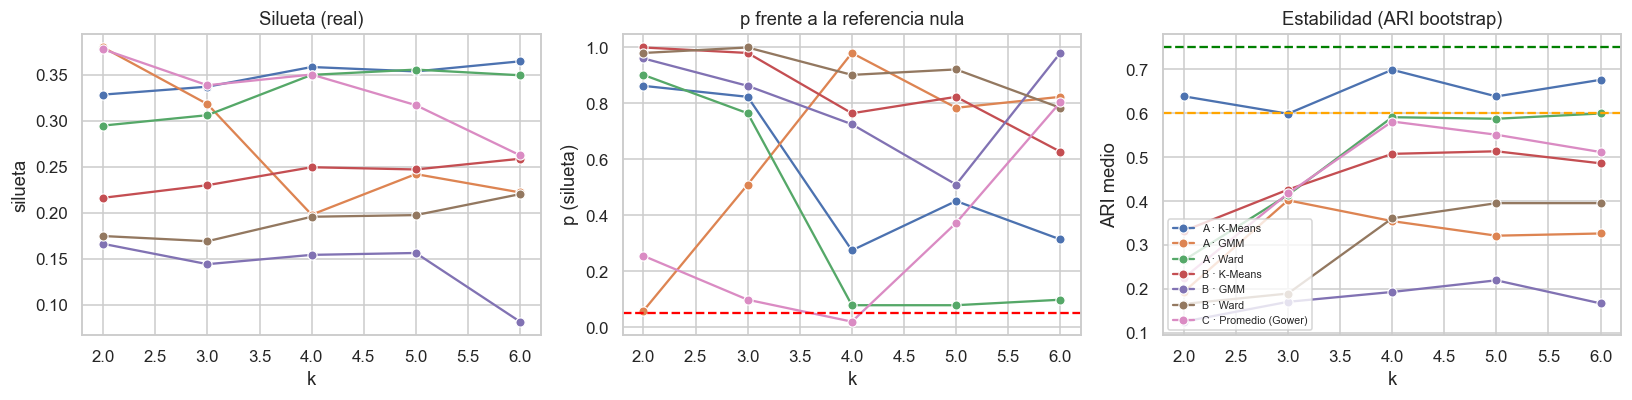

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sel["combinación"] = sel["conjunto"].str[:1] + " · " + sel["algoritmo"]
for a, (y, t) in zip(ax, [("silueta", "Silueta (real)"), ("p (silueta)", "p frente a la referencia nula"), ("ARI medio", "Estabilidad (ARI bootstrap)")]):
    sns.lineplot(data=sel, x="k", y=y, hue="combinación", marker="o", ax=a, legend=(a is ax[2])); a.set_title(t)
ax[1].axhline(0.05, ls="--", c="red"); ax[2].axhline(0.75, ls="--", c="green"); ax[2].axhline(0.6, ls="--", c="orange")
ax[2].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.savefig(FIG/"anexo6_seleccion_k.png", bbox_inches="tight"); plt.show()

## 4. Contraste basado en densidad: HDBSCAN
HDBSCAN no fija k: busca zonas densas separadas por zonas vacías y marca como **ruido** a los puntos aislados. Si hubiera grupos naturales, los encontraría.

In [7]:
hd = []
for mcs in [5, 8, 10, 15]:
    for cn in ["A. z", "B. z + cambio"]:
        lab = HDBSCAN(min_cluster_size=mcs).fit_predict(CONJ[cn][0])
        hd.append({"conjunto": cn, "min_cluster_size": mcs, "grupos": int(lab.max() + 1), "% ruido": round(100 * (lab == -1).mean(), 1)})
hd = pd.DataFrame(hd); hd

,conjunto,min_cluster_size,grupos,% ruido
0,A. z,5,2,33.8
1,B. z + cambio,5,2,83.9
2,A. z,8,2,71.2
3,B. z + cambio,8,0,100.0
4,A. z,10,2,74.1
5,B. z + cambio,10,0,100.0
6,A. z,15,0,100.0
7,B. z + cambio,15,0,100.0


**Interpretación.** HDBSCAN, que solo forma grupos donde hay zonas densas separadas, **no encuentra estructura**: según el parámetro, deja entre el 34 % y el 100 % de los niños como ruido, y en B no forma ningún grupo desde `min_cluster_size` = 8. Confirma, con un método de otra familia, que no hay grupos naturales.

### Decisión
Las cinco evidencias (Hopkins, BIC, silueta frente a la nula, estabilidad y HDBSCAN) coinciden: **no hay grupos naturales**. Aun así, una **segmentación** del continuo puede servir para describir y priorizar, siempre que sea estable e interpretable y que se presente como tal. Se elige **K-Means con k = 4 sobre los z (conjunto A)**:
- es la partición **más estable** de las 35 evaluadas (ARI 0,70);
- tiene los mejores índices internos de su conjunto (silueta 0,36, CH 87,9, DB 0,87) y su grupo más pequeño tiene 19 niños;
- usa solo dos variables en unidad OMS, así que cada centroide se lee directamente ("z de IMC +2, z de talla +0,5").

## 5. Segmentación elegida y comparación con los cortes de la OMS
Se ajusta la combinación elegida (ver interpretación de §1–4) y se **reordenan los grupos por su z de IMC medio** para que la numeración no dependa de la semilla. Luego se compara con la segmentación que ya usa la nutricionista: los **cortes de la OMS** sobre los mismos z (exceso de peso sí/no × talla baja sí/no). Si el ARI es alto, el clustering solo reproduce la regla.

In [8]:
ELEGIDO = ("A. z", "K-Means", 4)
km = KMeans(ELEGIDO[2], n_init=20, random_state=0).fit(A)
orden = np.argsort(np.argsort(km.cluster_centers_[:, 0]))
ninos["grupo"] = orden[km.labels_] + 1
exceso = ninos["cat_imc"].isin(["Sobrepeso", "Obesidad"]); talla_b = ninos["z_talla"] < -2
ninos["regla_oms"] = np.select([exceso & talla_b, exceso, talla_b], ["exceso + talla baja", "exceso", "talla baja"], "sin alteración")
ari_regla = adjusted_rand_score(ninos["regla_oms"], ninos["grupo"])
print(f"ARI grupos K-Means vs cortes OMS: {ari_regla:.3f}")
print(pd.crosstab(ninos["grupo"], ninos["regla_oms"], margins=True).to_string())

ARI grupos K-Means vs cortes OMS: 0.308
regla_oms  exceso  exceso + talla baja  sin alteración  talla baja  All
grupo                                                                  
1               0                    3              13          16   32
2               4                    0              39           0   43
3              29                    4              12           0   45
4              18                    0               1           0   19
All            51                    7              65          16  139


**Interpretación.** El ARI con los cortes de la OMS es **0,31**: los grupos no son una copia de la regla. La diferencia principal está en el exceso de peso: la OMS reparte los 51 niños con "solo exceso" entre los grupos 3 y 4, que se distinguen por la **talla** (ver §6), y los niños "sin alteración" se reparten entre los grupos 1, 2 y 3 según qué tan cerca estén de los cortes.

## 6. Perfiles
Centroide (z medio), tamaño y composición de cada grupo.

       niños  z_imc  z_talla  cambio_z_imc   edad  pct_varones  pct_exceso_oms  pct_talla_baja_oms
grupo                                                                                             
1         32   0.21    -2.23         -0.22  11.97         59.4             9.4                59.4
2         43   0.42    -0.31          0.11   9.70         53.5             9.3                 0.0
3         45   1.52    -1.32          0.30  10.31         46.7            73.3                 8.9
4         19   2.09     0.48         -0.04  10.48         78.9            94.7                 0.0


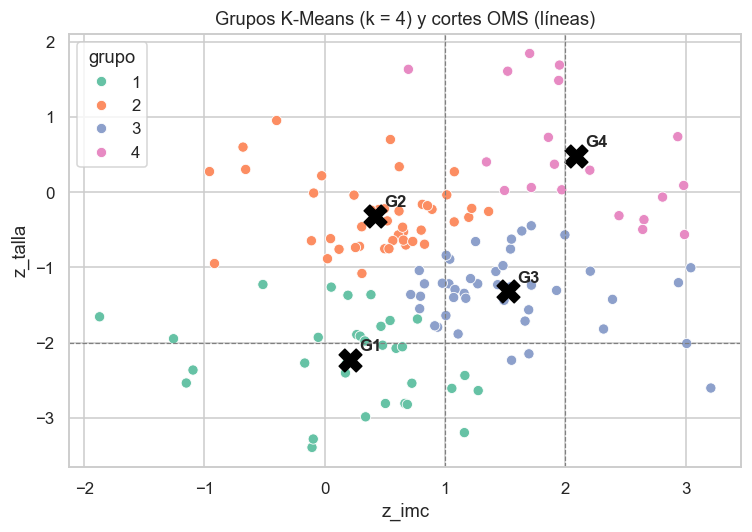

In [9]:
perfil = ninos.groupby("grupo").agg(niños=("id_nna","size"), z_imc=("z_imc","mean"), z_talla=("z_talla","mean"),
                                    cambio_z_imc=("cambio_z_imc","median"), edad=("edad","mean"), pct_varones=("sexo_m","mean"),
                                    pct_exceso_oms=("cat_imc", lambda s: s.isin(["Sobrepeso","Obesidad"]).mean()),
                                    pct_talla_baja_oms=("z_talla", lambda s: (s < -2).mean()))
for c in ["pct_varones","pct_exceso_oms","pct_talla_baja_oms"]: perfil[c] = (100 * perfil[c]).round(1)
perfil = perfil.round(2); print(perfil.to_string())
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=ninos, x="z_imc", y="z_talla", hue="grupo", palette="Set2", s=45, ax=ax)
ax.scatter(perfil["z_imc"], perfil["z_talla"], marker="X", s=220, c="black")
for g, r in perfil.iterrows(): ax.annotate(f"G{g}", (r["z_imc"], r["z_talla"]), xytext=(6, 6), textcoords="offset points", fontsize=11, weight="bold")
for v in (1, 2): ax.axvline(v, ls="--", c="gray", lw=.8)
ax.axhline(-2, ls="--", c="gray", lw=.8); ax.set_title("Grupos K-Means (k = 4) y cortes OMS (líneas)")
plt.tight_layout(); plt.savefig(FIG/"anexo6_perfiles.png", bbox_inches="tight"); plt.show()

**Perfiles (nombres propuestos para la nutricionista):**

| Grupo | Niños | z IMC | z talla | Lectura | Perfil |
|---|---|---|---|---|---|
| **G1** | 32 | +0,21 | **−2,23** | Peso adecuado para la talla, pero **talla baja** (59 % con z < −2) | **Retraso de talla** |
| **G2** | 43 | +0,42 | −0,31 | Cerca de lo esperado en ambas medidas (9 % con exceso, 0 % con talla baja) | **Dentro de lo esperado** |
| **G3** | 45 | **+1,52** | −1,32 | Exceso de peso (73 %) **con talla por debajo de lo esperado** | **Exceso con talla en riesgo** (doble carga) |
| **G4** | 19 | **+2,09** | +0,48 | Exceso marcado (95 %) con talla normal o alta; 79 % varones | **Exceso de peso** |

El aporte frente a la regla OMS es **G3**: 45 niños con exceso de peso cuya talla media (−1,32) está en la zona de riesgo. La regla los clasifica igual que a G4 ("exceso"), pero combinan dos problemas y probablemente necesiten otro manejo (exceso de peso con crecimiento lineal comprometido). Ningún grupo muestra un cambio en el tiempo marcado (mediana de `cambio_z_imc` entre −0,22 y +0,30 z por año).

## 7. Validación externa con la etiqueta de la ficha
La etiqueta **no participó** en la formación de los grupos. Si los grupos capturan estado nutricional, la proporción de niños con alteración registrada debería variar entre ellos.

In [10]:
v = ninos.dropna(subset=["ficha_alteracion_estricta"])
val = v.groupby("grupo").agg(niños_con_etiqueta=("id_nna","size"), pct_alteracion_estricta=("ficha_alteracion_estricta","mean"), pct_alteracion_amplia=("ficha_alteracion","mean"))
val[["pct_alteracion_estricta","pct_alteracion_amplia"]] = (100 * val[["pct_alteracion_estricta","pct_alteracion_amplia"]]).round(1)
ari_ficha = adjusted_rand_score(v["ficha_alteracion_estricta"], v["grupo"]); nmi_ficha = normalized_mutual_info_score(v["ficha_alteracion_estricta"], v["grupo"])
ari_regla_ficha = adjusted_rand_score(v["ficha_alteracion_estricta"], v["regla_oms"])
print(val.to_string()); print(f"\nARI / NMI grupos vs ficha: {ari_ficha:.3f} / {nmi_ficha:.3f} | ARI cortes OMS vs ficha: {ari_regla_ficha:.3f}")

       niños_con_etiqueta  pct_alteracion_estricta  pct_alteracion_amplia
grupo                                                                    
1                      30                     43.3                   86.7
2                      39                     10.3                   38.5
3                      41                     51.2                   70.7
4                      19                     68.4                   89.5

ARI / NMI grupos vs ficha: 0.088 / 0.099 | ARI cortes OMS vs ficha: 0.219


**Interpretación.** Los grupos **ordenan** la alteración registrada en la ficha: 10 % en G2 (dentro de lo esperado), frente a 43 % en G1, 51 % en G3 y 68 % en G4. Es decir, sin haber usado la etiqueta, el clustering separa a los niños con menos alteración registrada de los que tienen más. Pero la coincidencia global es baja (ARI 0,09; NMI 0,10), menor que la de los cortes OMS (ARI 0,22), porque la etiqueta estricta es binaria y los grupos 1, 3 y 4 son todos "con alteración" en distinto grado. Además, **la etiqueta amplia marca alteración en el 87 % de G1**, pero la estricta solo en el 43 %: la ficha suele registrar el retraso de talla como *riesgo* y no como *talla baja*.

## 8. Descripción con las variables de la ficha
Variables que **no** formaron los grupos. Se reportan proporciones y medias por grupo, con una prueba de asociación (χ² para categóricas, Kruskal-Wallis para numéricas) solo como orientación: con 139 niños y varias pruebas, un *p* < 0,05 aislado puede ser casualidad.

In [11]:
from scipy.stats import chi2_contingency, kruskal
desc, pruebas = {}, []
for c in ["anemia_alguna_vez","tiene_discapacidad","salud_mental_especializada"]:
    desc["% " + c] = ninos.groupby("grupo")[c].mean().mul(100).round(1)
    t = pd.crosstab(ninos["grupo"], ninos[c]); pruebas.append({"variable": c, "prueba": "χ²", "p": chi2_contingency(t)[1]})
for c in ["edad","tiempo_hogar_meses","n_tipos_soporte"]:
    desc[c + " (media)"] = ninos.groupby("grupo")[c].mean().round(1)
    pruebas.append({"variable": c, "prueba": "Kruskal-Wallis", "p": kruskal(*[g[c].dropna() for _, g in ninos.groupby("grupo")])[1]})
for c in ["casa","sexo_m"]:
    t = pd.crosstab(ninos["grupo"], ninos[c]); pruebas.append({"variable": c, "prueba": "χ²", "p": chi2_contingency(t)[1]})
print(pd.DataFrame(desc).to_string()); print()
print(pd.crosstab(ninos["grupo"], ninos["casa"]).to_string()); print()
pruebas = pd.DataFrame(pruebas).round(3); print(pruebas.to_string(index=False))

       % anemia_alguna_vez  % tiene_discapacidad  % salud_mental_especializada  edad (media)  tiempo_hogar_meses (media)  n_tipos_soporte (media)
grupo                                                                                                                                            
1                     21.9                  15.6                          18.8          12.0                        88.2                      1.0
2                      7.0                   7.0                           2.3           9.7                        66.4                      0.9
3                     11.1                   6.7                          11.1          10.3                        71.2                      0.6
4                     21.1                   0.0                          21.1          10.5                        63.4                      1.1

casa   INFANTES  MATOGROSO HOMBRES  MATOGROSO MUJERES  MIGUEL ECHENIQUE  TOMAS VALLE
grupo                                 

**Interpretación.** **Ninguna variable de la ficha se asocia con claridad a los grupos** (todos los *p* ≥ 0,06). Hay tendencias que convendría revisar con más datos: G1 (retraso de talla) tiene más tiempo en el hogar (88 meses de media frente a 63–71), más discapacidad (16 %) y más anemia alguna vez (22 %); G4 tiene más varones (79 %) y ninguno de sus 19 niños está en Miguel Echenique. Los grupos aparecen en **todos los hogares**: el estado nutricional no depende de una casa en particular. Es coherente con el avance, donde las variables de la ficha no explicaban la alteración.

## 9. Perfiles y auditoría
Se cruza cada grupo con la lista de discrepancias ficha vs. OMS del Step 5: ¿en qué perfil se concentran los niños cuya ficha no refleja sus mediciones?

In [12]:
aud = pd.read_csv(RES/"step5_auditoria_discrepancias.csv", sep="|")
ninos["en_auditoria"] = ninos["id_nna"].isin(aud["id_nna"]).astype(int)
ninos["subregistro"] = ninos["id_nna"].isin(aud.loc[aud["tipos"].str.contains("sin alteración"), "id_nna"]).astype(int)
cruce = v.assign(en_auditoria=ninos.set_index("id_nna").loc[v["id_nna"], "en_auditoria"].values,
                 subregistro=ninos.set_index("id_nna").loc[v["id_nna"], "subregistro"].values)
cruce = cruce.groupby("grupo").agg(niños_con_etiqueta=("id_nna","size"), pct_con_discrepancia=("en_auditoria","mean"), pct_subregistro=("subregistro","mean"))
cruce[["pct_con_discrepancia","pct_subregistro"]] = (100 * cruce[["pct_con_discrepancia","pct_subregistro"]]).round(1)
print(cruce.to_string())
ninos[["id_nna","grupo","regla_oms","z_imc","z_talla","cambio_z_imc","edad","sexo_m","casa","n_mediciones",
       "ficha_alteracion_estricta","en_auditoria","subregistro"]].to_csv(RES/"anexo6_grupos.csv", sep="|", index=False)
perfil.to_csv(RES/"anexo6_perfiles.csv", sep="|")

       niños_con_etiqueta  pct_con_discrepancia  pct_subregistro
grupo                                                           
1                      30                  50.0             43.3
2                      39                  25.6             17.9
3                      41                  68.3             26.8
4                      19                  63.2             26.3


**Interpretación.** Las discrepancias entre la ficha y la OMS **se concentran en los perfiles con alteración**: 50 % de los niños de G1, 68 % de G3 y 63 % de G4 tienen al menos una evaluación discrepante, frente a 26 % en G2. El dato más accionable es el **subregistro en G1**: en el **43 %** de los niños con retraso de talla, la ficha dice "sin alteración" mientras la medición OMS indica exceso o talla baja. Es el perfil que la ficha más subestima y el primero que conviene revisar con la nutricionista.

## 10. Selección de algoritmos (conclusión)

| Algoritmo / conjunto | Evidencia | Decisión |
|---|---|---|
| GMM (A, B) | BIC elige k = 1; ARI ≤ 0,40 | Descartado: confirma que no hay mezcla de poblaciones |
| Ward (A) | Índices parecidos a K-Means; ARI ≤ 0,60 | Comparador; menos estable |
| **K-Means, k = 4 (A)** | Silueta 0,36 (no supera la nula); **ARI 0,70**; perfiles interpretables | **Elegido como segmentación descriptiva** |
| Cualquiera con `cambio_z_imc` (B) | Todos los índices empeoran; ARI ≤ 0,51 | Descartado: el cambio entre 1 y 5 mediciones es ruido |
| Enlace promedio + Gower (C) | Aísla grupos de 1 a 6 niños; ARI ≤ 0,58 | Descartado: las variables de la ficha no agregan estructura |
| HDBSCAN (A, B) | 34–100 % de ruido | Descartado: no hay zonas densas separadas |

**Mensaje para el informe:** los NNA del Puericultorio no forman "tipos" nutricionales separados; forman un **continuo** desplazado hacia el exceso de peso y la talla baja (Step 4). Sobre ese continuo, K-Means con k = 4 da una segmentación moderadamente estable que **agrega a la regla OMS el perfil de doble carga (G3)** y señala dónde la ficha subregistra (G1).

**Para la entrega final (Steps 7–9):** fijar la segmentación con todas las mediciones del año (incluidas las que lleguen después de agosto) y comprobar si los niños se mantienen en su grupo de un mes a otro; validar los nombres de los perfiles y la lista G1 con la nutricionista; reportar los centroides con intervalos bootstrap. **Límites a declarar:** 139 niños, 1 a 5 mediciones por niño en 8 meses, sin grupos naturales (la segmentación es una herramienta descriptiva, no un hallazgo de tipos), etiqueta manual con rezago.

## Verificación y cifras de este notebook

In [13]:
r = sel.set_index(["conjunto","algoritmo","k"])
eleg = r.loc[ELEGIDO]
assert bic.loc[bic.groupby("conjunto")["BIC"].idxmin(), "k"].tolist() == [1, 1]
assert r["ARI medio"].idxmax() == ELEGIDO and round(eleg["ARI medio"], 2) == 0.70 and (r["ARI medio"] < 0.75).all()
assert round(eleg["silueta"], 2) == 0.36 and eleg["p (silueta)"] > 0.05 and int((r["p (silueta)"] < 0.05).sum()) == 1
assert hd["% ruido"].min() == 33.8 and round(ari_regla, 2) == 0.31
assert perfil["niños"].tolist() == [32, 43, 45, 19] and val["pct_alteracion_estricta"].tolist() == [43.3, 10.3, 51.2, 68.4]
assert round(ari_ficha, 2) == 0.09 and round(ari_regla_ficha, 2) == 0.22 and (pruebas["p"] >= 0.05).all()
assert cruce["pct_subregistro"].tolist() == [43.3, 17.9, 26.8, 26.3]
cifras = {"bic_k_optimo": 1, "ari_elegido": round(float(eleg["ARI medio"]), 3), "silueta_elegido": round(float(eleg["silueta"]), 3),
          "p_silueta_elegido": round(float(eleg["p (silueta)"]), 3), "ari_regla_oms": round(float(ari_regla), 3),
          "ari_ficha": round(float(ari_ficha), 3), "nmi_ficha": round(float(nmi_ficha), 3), "ari_regla_ficha": round(float(ari_regla_ficha), 3),
          "grupos_tamano": perfil["niños"].tolist(), "grupos_z_imc": perfil["z_imc"].tolist(), "grupos_z_talla": perfil["z_talla"].tolist(),
          "grupos_pct_alteracion_ficha": val["pct_alteracion_estricta"].tolist(), "grupos_pct_subregistro": cruce["pct_subregistro"].tolist(),
          "hdbscan_ruido_min": float(hd["% ruido"].min())}
json.dump(cifras, open(RES/"cifras_anexo6.json", "w"), indent=1); cifras

{'bic_k_optimo': 1,
 'ari_elegido': 0.699,
 'silueta_elegido': 0.359,
 'p_silueta_elegido': 0.275,
 'ari_regla_oms': 0.308,
 'ari_ficha': 0.088,
 'nmi_ficha': 0.099,
 'ari_regla_ficha': 0.219,
 'grupos_tamano': [32, 43, 45, 19],
 'grupos_z_imc': [0.21, 0.42, 1.52, 2.09],
 'grupos_z_talla': [-2.23, -0.31, -1.32, 0.48],
 'grupos_pct_alteracion_ficha': [43.3, 10.3, 51.2, 68.4],
 'grupos_pct_subregistro': [43.3, 17.9, 26.8, 26.3],
 'hdbscan_ruido_min': 33.8}